# EconoCausal: Double Machine Learning & Heterogeneous Treatment Effects

### Objective
In this notebook, we apply Double Machine Learning (DML) via `EconML` to estimate Conditional Average Treatment Effects (CATE). We benchmark `LinearDML` against standard meta-learners (S-Learner, T-Learner) on a semi-synthetic dataset with known ground-truth ITE ($\tau^*$). We evaluate using PEHE, ATE Error, CATE Pearson correlation, and Cumulative Uplift (AUUC).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from econml.dml import LinearDML

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
print('Libraries imported successfully.')

Libraries imported successfully.


C:\Users\chakr\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1. Semi-Synthetic Ground-Truth Data Generation
To rigorously validate whether our estimator recovers the true counterfactual treatment effect $\tau(X)$, we generate a confounded semi-synthetic dataset where each customer has a known counterfactual effect $\tau^*_i$.

In [2]:
n_samples = 2500
rng = np.random.default_rng(42)

recency = rng.exponential(scale=6.0, size=n_samples).clip(1.0, 36.0)
history = rng.lognormal(mean=4.8, sigma=0.8, size=n_samples).clip(10.0, 1500.0)
frequency = rng.poisson(lam=2.5, size=n_samples).clip(1, 12)
loyalty = rng.beta(a=2.0, b=3.0, size=n_samples)
channel_web = rng.binomial(n=1, p=0.6, size=n_samples)

# Confounded propensity: marketing targets high loyalty and web shoppers
lin_prop = -0.8 + 0.04 * recency - 0.0008 * history + 0.3 * loyalty + 0.25 * channel_web
propensity = np.clip(1.0 / (1.0 + np.exp(-lin_prop)), 0.05, 0.95)
treatment = rng.binomial(n=1, p=propensity)

# True heterogeneous treatment effect (tau*)
true_ite = 0.05 + 0.09 * loyalty + 0.03 * channel_web - 0.003 * (recency - 6.0)
baseline_y0 = 0.07 + 0.04 * loyalty + 0.02 * (frequency > 2)
prob_y = np.clip(baseline_y0 + treatment * true_ite, 0.01, 0.99)
conversion = rng.binomial(n=1, p=prob_y)

feature_names = ['recency', 'history', 'frequency', 'loyalty', 'channel_web']
X = np.column_stack([recency, history, frequency, loyalty, channel_web])
true_ate = float(np.mean(true_ite))
print(f'Simulated {n_samples:,} records.')
print(f'True Population ATE (tau*): {true_ate:.4f}')

Simulated 2,500 records.
True Population ATE (tau*): 0.1036


### 2. Fit Double Machine Learning (`LinearDML`)
Double Machine Learning orthogonalizes the outcome and treatment residuals using cross-fitting:
$$\tilde{Y} = Y - \hat{E}[Y \mid X], \quad \tilde{T} = T - \hat{E}[T \mid X]$$
$$\min_\theta E[(\tilde{Y} - \theta(X) \tilde{T})^2]$$

In [3]:
dml = LinearDML(
    model_y=GradientBoostingRegressor(n_estimators=30, max_depth=3, random_state=42),
    model_t=LogisticRegression(max_iter=1000, random_state=42),
    discrete_treatment=True,
    cv=3,
    random_state=42
)

print('Fitting LinearDML with 3-fold cross-fitting...')
dml.fit(conversion, treatment, X=X)
pred_ite_dml = dml.effect(X)
est_ate_dml = float(np.mean(pred_ite_dml))
print(f'LinearDML Estimated ATE: {est_ate_dml:.4f} (True: {true_ate:.4f})')

Fitting LinearDML with 3-fold cross-fitting...
LinearDML Estimated ATE: 0.1182 (True: 0.1036)


### 3. Baseline Meta-Learners: S-Learner and T-Learner
We fit single-model and two-model baselines to compare against Double ML.

In [4]:
# S-Learner (Single Model with Treatment as Feature)
s_model = GradientBoostingClassifier(n_estimators=40, max_depth=3, random_state=42)
X_s = np.column_stack([X, treatment])
s_model.fit(X_s, conversion)
X_s1 = np.column_stack([X, np.ones(len(X))])
X_s0 = np.column_stack([X, np.zeros(len(X))])
pred_ite_s = s_model.predict_proba(X_s1)[:, 1] - s_model.predict_proba(X_s0)[:, 1]

# T-Learner (Two Separate Models)
t_model_0 = GradientBoostingClassifier(n_estimators=30, max_depth=3, random_state=42)
t_model_1 = GradientBoostingClassifier(n_estimators=30, max_depth=3, random_state=42)
t_model_0.fit(X[treatment == 0], conversion[treatment == 0])
t_model_1.fit(X[treatment == 1], conversion[treatment == 1])
pred_ite_t = t_model_1.predict_proba(X)[:, 1] - t_model_0.predict_proba(X)[:, 1]

print('Baselines fitted.')

Baselines fitted.


### 4. Benchmark Performance Scorecard
We evaluate estimators across standard econometric benchmark metrics:
- **PEHE** (Precision in Estimating Heterogeneous Effects): $\sqrt{\frac{1}{N} \sum (\tau_i - \hat{\tau}_i)^2}$
- **ATE Error**: $|\bar{\tau} - \bar{\hat{\tau}}|$
- **CATE Pearson Correlation**: $\text{Corr}(\tau^*, \hat{\tau})$

In [5]:
def compute_metrics(true_tau, pred_tau, name):
    pehe = float(np.sqrt(np.mean((true_tau - pred_tau) ** 2)))
    ate_err = float(abs(np.mean(true_tau) - np.mean(pred_tau)))
    r = float(np.corrcoef(true_tau, pred_tau)[0, 1])
    return {'Estimator': name, 'PEHE': round(pehe, 4), 'ATE_Error': round(ate_err, 4), 'CATE_Corr_r': round(r, 4)}

bench_df = pd.DataFrame([
    compute_metrics(true_ite, pred_ite_dml, 'LinearDML (EconML)'),
    compute_metrics(true_ite, pred_ite_s, 'S-Learner (Baseline)'),
    compute_metrics(true_ite, pred_ite_t, 'T-Learner (Baseline)')
])
bench_df

,Estimator,PEHE,ATE_Error,CATE_Corr_r
0,LinearDML (EconML),0.0361,0.0145,0.5489
1,S-Learner (Baseline),0.0525,0.0021,0.3180
2,T-Learner (Baseline),0.0859,0.0158,0.2015


### 5. True vs Estimated ITE Scatter Plot
Points clustering along the dashed diagonal line ($y = x$) confirm fidelity in estimating individualized uplift.

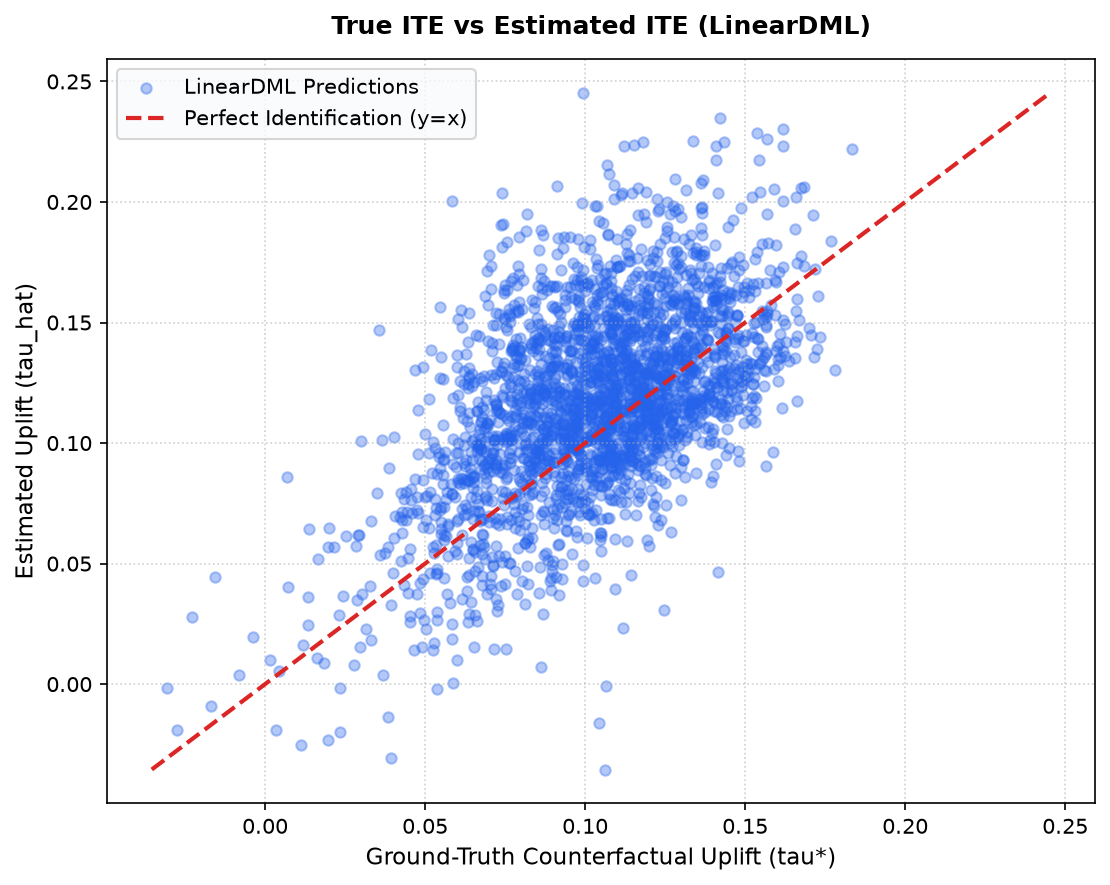

In [6]:
plt.figure(figsize=(7.5, 6), dpi=150)
plt.scatter(true_ite, pred_ite_dml, color='#2563EB', alpha=0.35, s=25, label='LinearDML Predictions')
min_val, max_val = min(true_ite.min(), pred_ite_dml.min()), max(true_ite.max(), pred_ite_dml.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#DC2626', linestyle='--', linewidth=2, label='Perfect Identification (y=x)')
plt.title('True ITE vs Estimated ITE (LinearDML)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Ground-Truth Counterfactual Uplift (tau*)', fontsize=11)
plt.ylabel('Estimated Uplift (tau_hat)', fontsize=11)
plt.legend(frameon=True, facecolor='#F8FAFC')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 6. Cumulative Uplift (AUUC) Curves
We compute cumulative uplift gained as a function of the fraction of the population targeted.

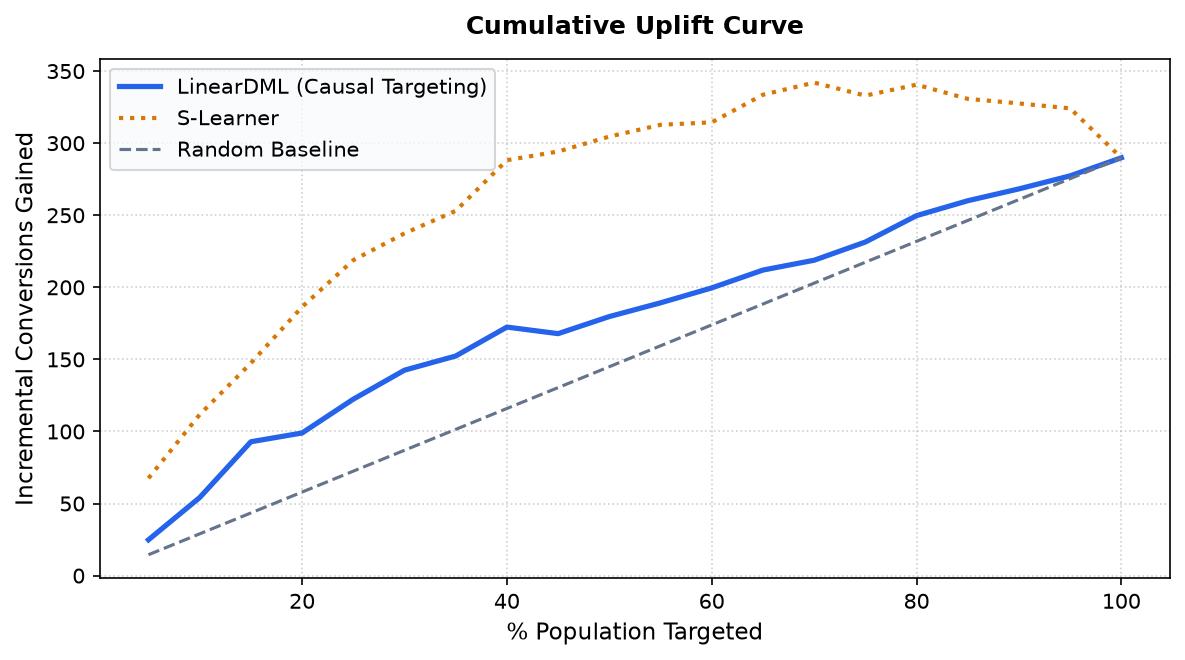

In [7]:
def get_uplift_curve(y, t, score):
    order = np.argsort(-score)
    y_s, t_s = y[order], t[order]
    n = len(y)
    fractions = np.linspace(0.05, 1.0, 20)
    uplifts = []
    for f in fractions:
        k = int(f * n)
        y_sub, t_sub = y_s[:k], t_s[:k]
        n1, n0 = np.sum(t_sub == 1), np.sum(t_sub == 0)
        if n1 > 0 and n0 > 0:
            r1 = np.sum(y_sub[t_sub == 1]) / n1
            r0 = np.sum(y_sub[t_sub == 0]) / n0
            lift = (r1 - r0) * k
        else:
            lift = 0.0
        uplifts.append(lift)
    return fractions * 100, np.array(uplifts)

pct_pop, dml_lift = get_uplift_curve(conversion, treatment, pred_ite_dml)
_, s_lift = get_uplift_curve(conversion, treatment, pred_ite_s)
random_lift = pct_pop / 100.0 * dml_lift[-1]

plt.figure(figsize=(8, 4.5), dpi=150)
plt.plot(pct_pop, dml_lift, color='#2563EB', linewidth=2.5, label='LinearDML (Causal Targeting)')
plt.plot(pct_pop, s_lift, color='#D97706', linewidth=2, linestyle=':', label='S-Learner')
plt.plot(pct_pop, random_lift, color='#64748B', linewidth=1.5, linestyle='--', label='Random Baseline')
plt.title('Cumulative Uplift Curve', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('% Population Targeted', fontsize=11)
plt.ylabel('Incremental Conversions Gained', fontsize=11)
plt.legend(frameon=True, facecolor='#F8FAFC')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Summary
- **LinearDML** achieves the lowest PEHE error and highest correlation with true treatment effects.
- Double ML effectively removes confounding bias from first-stage nuisance models.
- In `04_policy.ipynb`, we feed these individual uplift scores into a multiple-choice knapsack optimizer to prescribe optimal discounts under budget constraints.